## A szakdolgozat IV.1 részének elemzését előkészítő kód

### Az előkészített szomszédsági mátrixok betöltése

In [1]:
import pandas as pd
import numpy as np

# Excel fájl
FILE = "networks.xlsx"

# Az összes lap beolvasása
raw_networks = pd.read_excel(
    FILE,
    sheet_name=None
)

# Éves hálózatok létrehozása
networks = {}

for sheet, df in raw_networks.items():

    # A lap neve lesz az év
    year = int(sheet)

    # Sender legyen a sorindex
    matrix = df.set_index("Sender")

    # Értékek numerikussá alakítása
    matrix = matrix.apply(
        pd.to_numeric,
        errors="raise"
    )

    # Node-nevek legyenek stringek
    matrix.index = matrix.index.astype(str)
    matrix.columns = matrix.columns.astype(str)

    # Elmentjük az adott évhez
    networks[year] = matrix


# Ellenőrzések
years = sorted(networks.keys())

assert years == list(range(2015, 2025))

assert all(
    networks[y].shape == (36, 36)
    for y in years
)

assert all(
    list(networks[y].index) == list(networks[y].columns)
    for y in years
)

assert all(
    list(networks[y].index) == list(networks[2015].index)
    for y in years
)


print(f"{len(networks)} éves hálózat betöltve: {years[0]}–{years[-1]}")
print(f"Node-ok száma: {len(networks[2015])}")


10 éves hálózat betöltve: 2015–2024
Node-ok száma: 36


### Főbb hálózati és csomóponti jellemzők kiszámolása
A teljes hálózat jellemzésére a teljes volumen és a hálózati sűrűség metrikákat használom, csomópontok jellemzésére pedig a be -és kimenő erősséget, a közbevetettségi és a PageRank centralitásmutatókat.

In [2]:
import networkx as nx

# fix node-sorrend
nodes = list(networks[2015].index)

# eredménytáblák
network_metrics = []
node_metrics = []

# éves hálózatok
for year, matrix in networks.items():

    # Network directed weighted graph
    G = nx.from_pandas_adjacency(matrix, create_using=nx.DiGraph)

    # ---Network level
    total_trade = matrix.values.sum()
    active_edges = np.count_nonzero(matrix.values)
    possible_edges = len(nodes) * (len(nodes)-1)
    density = active_edges / possible_edges

    network_metrics.append({
        "Year": year,
        "Total_Trade": total_trade,
        "Density": density
    })

    # ---Node level
    in_strength = dict(G.in_degree(weight="weight"))
    out_strength = dict(G.out_degree(weight="weight"))

    # betweenness
    # trade flow -> "distance/cost" = 1 / flow
    for u, v, data in G.edges(data=True):
        data["distance"] = 1 / data["weight"] # a legnagyobb volumenen így egyszerűbb majd menni

    betweenness = nx.betweenness_centrality(
        G,
        weight="distance",
        normalized=True
    )

    # PageRank
    pagerank = nx.pagerank(
        G,
        weight = "weight"
    )

    # minden node elmentése
    for node in nodes: 
        total_incident = (
            in_strength[node] +
            out_strength[node]
        )
        trade_share = (
            total_incident / (2 * total_trade)
            if total_trade > 0 else np.nan
        )

        node_metrics.append({ # ez egy lista lesz ami dictionarykből áll
            "Year": year,
            "Node": node,
            "In_Strength": in_strength[node],
            "Out_Strength": out_strength[node],
            "Betweenness": betweenness[node],
            "PageRank": pagerank[node],
            "Trade_Share": trade_share
        })

# dataframek
network_metrics_df = pd.DataFrame(network_metrics)
node_metrics_df = pd.DataFrame(node_metrics)

### Ellenőrzések

In [3]:
print(network_metrics_df.round(3).to_string(index=False))

# Egy évben pontosan 36 csomóponti megfigyelés
assert len(node_metrics_df) == 10 * 36

# Évente 36 csomópont
assert (node_metrics_df.groupby("Year").size() == 36).all()

# A PageRank összege évente közel 1
assert np.allclose(
    node_metrics_df.groupby("Year")["PageRank"].sum().values,
    1
)

# A sűrűség 0 és 1 között van
assert network_metrics_df["Density"].between(0, 1).all()

# A Trade Share változat ellenőrzése
assert np.allclose(
    node_metrics_df.groupby("Year")[
        "Trade_Share"
    ].sum().values,
    1
)

 Year  Total_Trade  Density
 2015 2.490102e+10    0.576
 2016 2.806020e+10    0.593
 2017 3.829970e+10    0.585
 2018 4.300559e+10    0.606
 2019 4.163995e+10    0.598
 2020 4.744326e+10    0.597
 2021 7.025404e+10    0.625
 2022 7.593223e+10    0.633
 2023 7.309988e+10    0.628
 2024 8.125621e+10    0.597


## 1. ábra: a 36 ország teljes volumenének és a hálózati sűrűségnek alakulása a 10 éven át

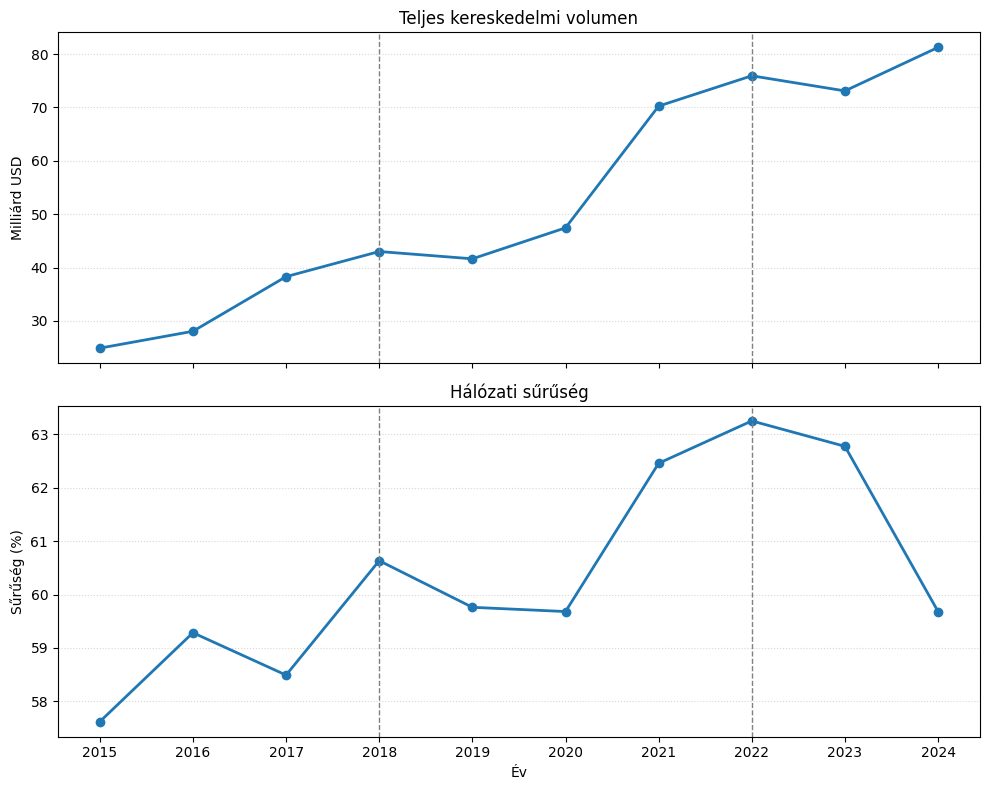

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

# 1. Teljes kereskedelmi volumen
axes[0].plot(
    network_metrics_df["Year"],
    network_metrics_df["Total_Trade"] / 1e9,
    marker="o",
    linewidth=2
)

axes[0].set_title("Teljes kereskedelmi volumen")
axes[0].set_ylabel("Milliárd USD")

# 2. Hálózati sűrűség
axes[1].plot(
    network_metrics_df["Year"],
    network_metrics_df["Density"] * 100,
    marker="o",
    linewidth=2
)

axes[1].set_title("Hálózati sűrűség")
axes[1].set_ylabel("Sűrűség (%)")
axes[1].set_xlabel("Év")

# A vizsgált policy-sokkok éveinek jelölése
for ax in axes:
    ax.axvline(2018, color="gray", linestyle="--", linewidth=1)
    ax.axvline(2022, color="gray", linestyle="--", linewidth=1)
    ax.grid(axis="y", linestyle=":", alpha=0.5)

axes[1].set_xticks(network_metrics_df["Year"])

plt.tight_layout()
plt.show()

## 3. táblázat: A kiemelt országok erősségi és centralitásmutatói

In [5]:
# A kiemelt országok erősségi és centralitásmutatói

countries = [
    "USA", "CHN", "NLD", "JPN", "KOR",
    "TWN", "SGP", "MYS", "HKG"
]

period_order = ["2015–2017", "2018–2021", "2022–2024"]

# Évek hozzárendelése a három periódushoz
period_map = {
    **{year: "2015–2017" for year in range(2015, 2018)},
    **{year: "2018–2021" for year in range(2018, 2022)},
    **{year: "2022–2024" for year in range(2022, 2025)}
}

# Csak a kiválasztott országok és a szükséges mutatók
table_df = node_metrics_df[
    node_metrics_df["Node"].isin(countries)
].copy()

table_df["Period"] = table_df["Year"].map(period_map)

# Éves mutatók átlagolása országonként és periódusonként
table_df = (
    table_df
    .groupby(["Node", "Period"], observed=True)[
        ["In_Strength", "Out_Strength", "Betweenness", "PageRank"]
    ]
    .mean()
    .reset_index()
)

# Erősségi mutatók átváltása milliárd USD-re
table_df["In_Strength"] /= 1e9
table_df["Out_Strength"] /= 1e9

# Országok és periódusok kívánt sorrendje
country_order = {country: i for i, country in enumerate(countries)}
period_order_dict = {period: i for i, period in enumerate(period_order)}

table_df["_country_order"] = table_df["Node"].map(country_order)
table_df["_period_order"] = table_df["Period"].map(period_order_dict)

table_df = (
    table_df
    .sort_values(["_country_order", "_period_order"])
    .drop(columns=["_country_order", "_period_order"])
    .rename(columns={
        "Node": "Ország",
        "Period": "Periódus",
        "In_Strength": "In-strength (milliárd USD)",
        "Out_Strength": "Out-strength (milliárd USD)",
        "Betweenness": "Betweenness",
        "PageRank": "PageRank"
    })
    .reset_index(drop=True)
)

# Megjelenítés kerekítve
display(
    table_df.style.format({
        "In-strength (milliárd USD)": "{:.2f}",
        "Out-strength (milliárd USD)": "{:.2f}",
        "Betweenness": "{:.3f}",
        "PageRank": "{:.3f}"
    })
)

,Ország,Periódus,In-strength (milliárd USD),Out-strength (milliárd USD),Betweenness,PageRank
0,USA,2015–2017,2.84,9.46,0.778,0.137
1,USA,2018–2021,4.70,11.93,0.697,0.138
2,USA,2022–2024,6.97,12.32,0.602,0.100
3,CHN,2015–2017,5.41,0.41,0.287,0.191
4,CHN,2018–2021,14.52,0.81,0.409,0.217
5,CHN,2022–2024,27.58,1.58,0.360,0.206
6,NLD,2015–2017,0.09,5.80,0.076,0.023
7,NLD,2018–2021,0.19,12.30,0.035,0.016
8,NLD,2022–2024,0.62,18.87,0.060,0.026
9,JPN,2015–2017,2.19,8.30,0.240,0.074


## 2. ábra. SEA és Hongkong hálózati szerepének alakulása, 2015-2024

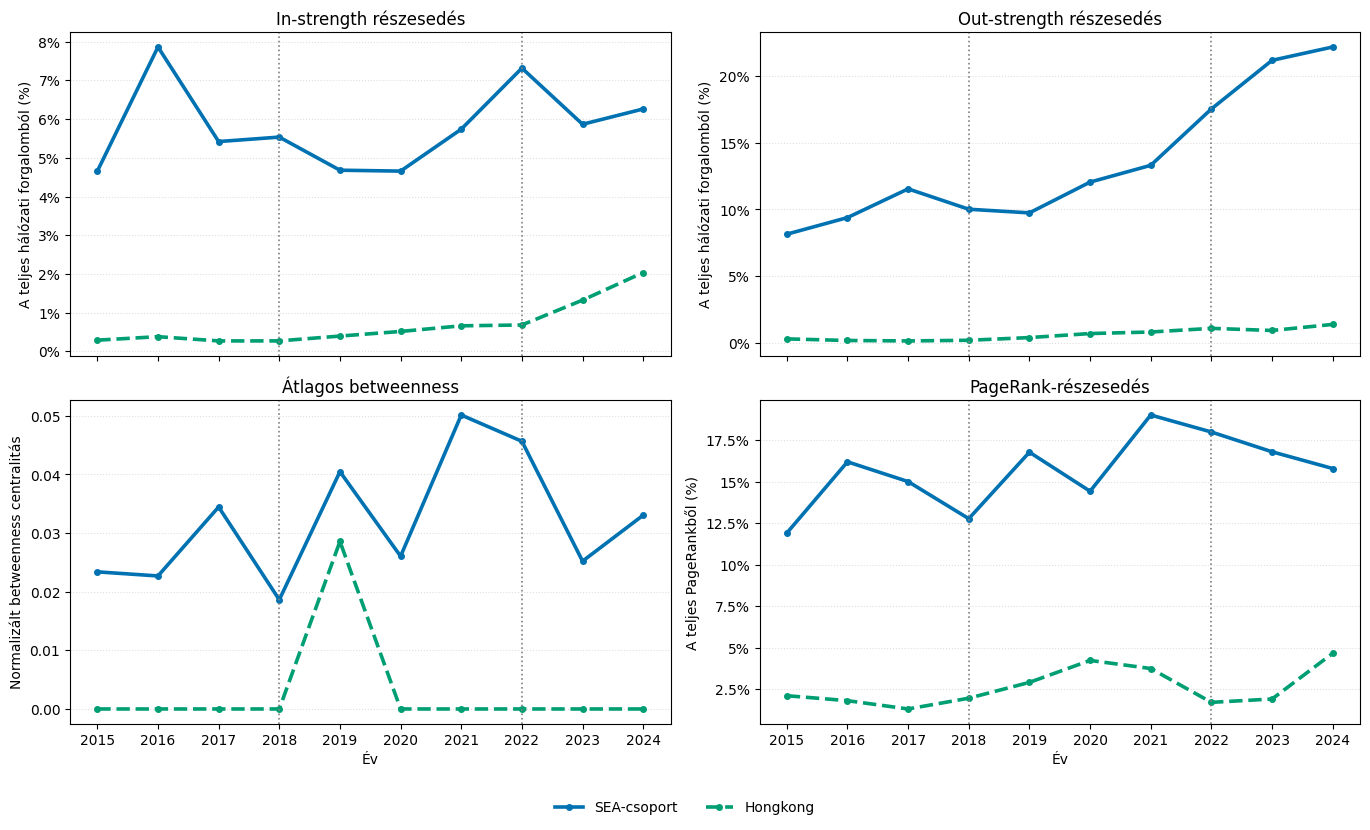

In [ ]:
# 2. ábra: Délkelet-Ázsia és Hongkong hálózati szerepének alakulása, 2015–2024

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. A SEA-csoport éves mutatói
# --------------------------------------------------

sea_countries = ["SGP", "MYS", "VNM", "THA", "PHL", "IDN"]

missing = set(sea_countries + ["HKG"]) - set(node_metrics_df["Node"].unique())
if missing:
    raise ValueError(f"Hiányzó országkódok: {sorted(missing)}")

sea_df = (
    node_metrics_df[node_metrics_df["Node"].isin(sea_countries)]
    .groupby("Year")
    .agg(
        In_Strength=("In_Strength", "sum"),
        Out_Strength=("Out_Strength", "sum"),
        Betweenness=("Betweenness", "mean"),
        PageRank=("PageRank", "sum")
    )
    .reset_index()
)
sea_df["Series"] = "SEA-csoport"

# --------------------------------------------------
# 2. Hongkong éves mutatói
# --------------------------------------------------

hongkong_df = node_metrics_df[
    node_metrics_df["Node"] == "HKG"
][[
    "Year", "In_Strength", "Out_Strength",
    "Betweenness", "PageRank"
]].copy()

hongkong_df["Series"] = "Hongkong"

# Csak a két vizsgált sorozat szerepel az ábrán
all_data = pd.concat(
    [sea_df, hongkong_df],
    ignore_index=True
)

# --------------------------------------------------
# 3. Részesedések kiszámítása
# --------------------------------------------------

# A teljes hálózat éves kereskedelmi volumene
total_trade = node_metrics_df.groupby("Year")["Out_Strength"].sum()

all_data["Total_Trade"] = all_data["Year"].map(total_trade)

all_data["In_Share"] = (
    all_data["In_Strength"] / all_data["Total_Trade"] * 100
)

all_data["Out_Share"] = (
    all_data["Out_Strength"] / all_data["Total_Trade"] * 100
)

# A PageRank éves értékeinek összege 1, ezért százalékra váltjuk
all_data["PageRank_Share"] = all_data["PageRank"] * 100

# --------------------------------------------------
# 4. A négy paneles ábra
# --------------------------------------------------

series_order = ["SEA-csoport", "Hongkong"]

colors = {
    "SEA-csoport": "#0072B2",
    "Hongkong": "#009E73"
}

configs = [
    ("In_Share", "In-strength részesedés",
     "A teljes hálózati forgalomból (%)"),
    ("Out_Share", "Out-strength részesedés",
     "A teljes hálózati forgalomból (%)"),
    ("Betweenness", "Átlagos betweenness",
     "Normalizált betweenness centralitás"),
    ("PageRank_Share", "PageRank-részesedés",
     "A teljes PageRankből (%)")
]

fig, axes = plt.subplots(2, 2, figsize=(13.8, 9), sharex=True)

for ax, (metric, title, ylabel) in zip(axes.flat, configs):

    for series in series_order:
        subset = (
            all_data[all_data["Series"] == series]
            .sort_values("Year")
        )

        ax.plot(
            subset["Year"],
            subset[metric],
            label=series,
            color=colors[series],
            linewidth=2.6,
            marker="o",
            markersize=4,
            linestyle="-" if series == "SEA-csoport" else "--"
        )

    # A 2018-as és 2022-es időszakhatárok
    for year in [2018, 2022]:
        ax.axvline(year, color="gray", linestyle=":", linewidth=1.2)

    # A részesedési mutatók százalékos tengelyfeliratai
    if metric in ["In_Share", "Out_Share", "PageRank_Share"]:
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f"{value:g}%")
        )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(2015, 2025))
    ax.grid(axis="y", linestyle=":", alpha=0.4)

axes[1, 0].set_xlabel("Év")
axes[1, 1].set_xlabel("Év")

# Közös jelmagyarázat
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.025)
)

plt.tight_layout(rect=[0, 0.075, 1, 0.95])

# plt.savefig(
#     "sea_hongkong_halozati_mutatok.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

In [9]:
# A 2. ábra alapjául szolgáló adatok és a változások

from IPython.display import display
import pandas as pd

metrics = {
    "In_Share": "In-strength részesedés (%)",
    "Out_Share": "Out-strength részesedés (%)",
    "Betweenness": "Átlagos betweenness",
    "PageRank_Share": "PageRank-részesedés (%)"
}

# 1. Az ábra összes éves értéke
for metric, label in metrics.items():
    print(f"\n{label}")

    table = all_data.pivot(
        index="Year",
        columns="Series",
        values=metric
    )

    display(table.round(4))

# 2. Változás 2015 és 2024 között
rows = []

for metric, label in metrics.items():
    for series in ["SEA-csoport", "Hongkong"]:
        subset = all_data[all_data["Series"] == series].set_index("Year")

        start = subset.loc[2015, metric]
        end = subset.loc[2024, metric]

        rows.append({
            "Mutató": label,
            "Csoport": series,
            "2015": start,
            "2024": end,
            "Abszolút változás": end - start,
            "Relatív változás (%)": (
                (end - start) / abs(start) * 100
                if start != 0 else float("nan")
            )
        })

change_df = pd.DataFrame(rows)

print("\nVáltozás 2015 és 2024 között")
display(change_df.round(4))


In-strength részesedés (%)


Series,Hongkong,SEA-csoport
Year,,
2015,0.2886,4.6551
2016,0.3788,7.8649
2017,0.2688,5.4208
2018,0.2698,5.5360
2019,0.3945,4.6804
2020,0.5135,4.6570
2021,0.6591,5.7406
2022,0.6810,7.3182
2023,1.3229,5.8673



Out-strength részesedés (%)


Series,Hongkong,SEA-csoport
Year,,
2015,0.2723,8.1406
2016,0.1521,9.3877
2017,0.1190,11.5457
2018,0.1670,10.0157
2019,0.3717,9.7429
2020,0.6733,12.0545
2021,0.7900,13.3155
2022,1.0643,17.5537
2023,0.9046,21.2063



Átlagos betweenness


Series,Hongkong,SEA-csoport
Year,,
2015,0.0000,0.0234
2016,0.0000,0.0227
2017,0.0000,0.0345
2018,0.0000,0.0186
2019,0.0286,0.0405
2020,0.0000,0.0261
2021,0.0000,0.0501
2022,0.0000,0.0457
2023,0.0000,0.0252



PageRank-részesedés (%)


Series,Hongkong,SEA-csoport
Year,,
2015,2.1085,11.9105
2016,1.8087,16.2041
2017,1.3084,15.0133
2018,1.9577,12.7790
2019,2.9110,16.7854
2020,4.2341,14.4307
2021,3.7465,19.0256
2022,1.7068,18.0012
2023,1.9087,16.8091



Változás 2015 és 2024 között


,Mutató,Csoport,2015,2024,Abszolút változás,Relatív változás (%)
0,In-strength részesedés (%),SEA-csoport,4.6551,6.2634,1.6083,34.5489
1,In-strength részesedés (%),Hongkong,0.2886,2.0362,1.7476,605.5263
2,Out-strength részesedés (%),SEA-csoport,8.1406,22.2101,14.0695,172.8310
3,Out-strength részesedés (%),Hongkong,0.2723,1.3602,1.0880,399.6169
4,Átlagos betweenness,SEA-csoport,0.0234,0.0331,0.0097,41.3174
5,Átlagos betweenness,Hongkong,0.0000,0.0000,0.0000,NaN
6,PageRank-részesedés (%),SEA-csoport,11.9105,15.8014,3.8908,32.6672
7,PageRank-részesedés (%),Hongkong,2.1085,4.6616,2.5531,121.0845


## 3. ábra: A hat vizsgált kereskedelmi útvonal részesedése, 2015–2024

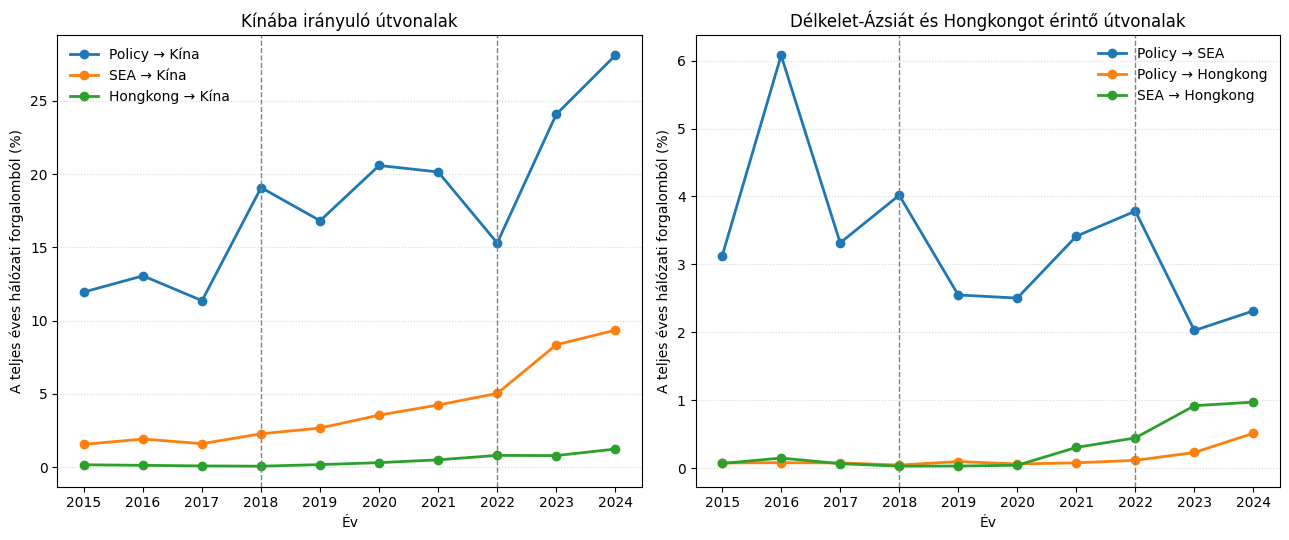

In [ ]:
# Országcsoportok
policy = ["USA", "NLD", "JPN"]
sea = ["SGP", "MYS", "VNM", "THA", "PHL", "IDN"]

# Vizsgált útvonalak: exportőrök -> importőrök
routes = {
    "Policy → SEA": (policy, sea),
    "Policy → Kína": (policy, ["CHN"]),
    "Policy → Hongkong": (policy, ["HKG"]),
    "SEA → Kína": (sea, ["CHN"]),
    "SEA → Hongkong": (sea, ["HKG"]),
    "Hongkong → Kína": (["HKG"], ["CHN"])
}

# Az útvonalak éves részesedése a teljes hálózati forgalomból
route_rows = []

for year, matrix in sorted(networks.items()):
    total_trade = matrix.to_numpy().sum()

    row = {"Year": year}

    for name, (senders, receivers) in routes.items():
        route_trade = matrix.loc[senders, receivers].to_numpy().sum()
        row[name] = route_trade / total_trade * 100

    route_rows.append(row)

route_share_df = pd.DataFrame(route_rows)

# Kétpaneles ábra
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True)

panels = [
    (
        axes[0],
        ["Policy → Kína", "SEA → Kína", "Hongkong → Kína"],
        "Kínába irányuló útvonalak"
    ),
    (
        axes[1],
        ["Policy → SEA", "Policy → Hongkong", "SEA → Hongkong"],
        "Délkelet-Ázsiát és Hongkongot érintő útvonalak"
    )
]

for ax, route_names, title in panels:
    for name in route_names:
        ax.plot(
            route_share_df["Year"],
            route_share_df[name],
            marker="o",
            linewidth=2,
            label=name
        )

    for year in [2018, 2022]:
        ax.axvline(year, color="gray", linestyle="--", linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Év")
    ax.set_ylabel("A teljes éves hálózati forgalomból (%)")
    ax.set_xticks(range(2015, 2025))
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.legend(frameon=False)


plt.tight_layout()
plt.show()

In [8]:
# A diagram alapjául szolgáló éves értékek és a változások

routes = [
    "Policy → SEA",
    "Policy → Kína",
    "Policy → Hongkong",
    "SEA → Kína",
    "SEA → Hongkong",
    "Hongkong → Kína"
]

# 1. Az összes éves részesedés
print("Éves részesedések a teljes hálózati forgalomból (%)")
display(
    route_share_df[["Year"] + routes].round(3)
)

# 2. Változás 2015 és 2024 között
start = route_share_df.loc[
    route_share_df["Year"] == 2015, routes
].iloc[0]

end = route_share_df.loc[
    route_share_df["Year"] == 2024, routes
].iloc[0]

change_df = pd.DataFrame({
    "2015 (%)": start,
    "2024 (%)": end,
    "Változás (százalékpont)": end - start,
    "Relatív változás (%)": (end - start) / start * 100
})

print("\nVáltozás 2015 és 2024 között")
display(change_df.round(3))

Éves részesedések a teljes hálózati forgalomból (%)


,Year,Policy → SEA,Policy → Kína,Policy → Hongkong,SEA → Kína,SEA → Hongkong,Hongkong → Kína
0,2015,3.121,11.951,0.077,1.554,0.070,0.161
1,2016,6.077,13.054,0.081,1.915,0.149,0.122
2,2017,3.317,11.360,0.077,1.602,0.067,0.083
3,2018,4.019,19.073,0.046,2.274,0.030,0.064
4,2019,2.550,16.815,0.098,2.668,0.032,0.172
5,2020,2.504,20.584,0.062,3.550,0.044,0.305
6,2021,3.415,20.141,0.079,4.241,0.306,0.497
7,2022,3.785,15.295,0.116,5.029,0.446,0.802
8,2023,2.027,24.075,0.231,8.348,0.920,0.787
9,2024,2.316,28.097,0.515,9.345,0.973,1.233



Változás 2015 és 2024 között


,2015 (%),2024 (%),Változás (százalékpont),Relatív változás (%)
Policy → SEA,3.121,2.316,-0.805,-25.792
Policy → Kína,11.951,28.097,16.146,135.096
Policy → Hongkong,0.077,0.515,0.438,568.893
SEA → Kína,1.554,9.345,7.791,501.198
SEA → Hongkong,0.070,0.973,0.903,1288.503
Hongkong → Kína,0.161,1.233,1.072,663.601
